In [12]:
import numpy as np
import matplotlib.pyplot as plt

In [13]:
e=3.795
hbar_c=1973.0
mc2=0.511e6

hbar2_over_2m=(hbar_c**2)/(2*mc2)

In [14]:
def hamiltonian_matrix(delta_r,potential_values):
    potential_values=np.asarray(potential_values,dtype=float)

    interior_points=len(potential_values)
    main_diag=(2*hbar2_over_2m)/(delta_r**2)+potential_values
    off_diag=np.full(interior_points-1,(-1*hbar2_over_2m)/(delta_r**2))
    hamiltonian=(np.diag(main_diag)+np.diag(off_diag,k=1)+np.diag(off_diag,k=-1))
    return hamiltonian

In [15]:
def effective_potential(r,l,potential):
    potential_values=potential+hbar2_over_2m*(l*(l+1)/(r**2))
    return potential_values

In [16]:
def hydrogen_atom(r):
    return -e**2/r


def solve_potential(ri,rf,interior_points,l,state_index):
    delta_r=(rf-ri)/(interior_points+1)
    interior_grid=ri+delta_r*np.arange(1,interior_points+1)

    potential=hydrogen_atom(interior_grid)
    potential_values=effective_potential(interior_grid,l,potential)

    H=hamiltonian_matrix(delta_r,potential_values)
    eigenvalues,eigenvectors=np.linalg.eigh(H)

    phi_interior=eigenvectors[:,state_index]

    if phi_interior[np.argmax(np.abs(phi_interior))]<0:
        phi_interior=-phi_interior

    energy_value=eigenvalues[state_index]

    phi=np.concatenate(([0],phi_interior,[0]))
    normalization=np.sum(np.abs(phi)**2)*delta_r
    phi_normalized=phi/np.sqrt(normalization)

    R_interior=phi_interior/interior_grid
    norm_3d=np.sum(np.abs(R_interior)**2*interior_grid**2)*delta_r
    R_interior_normalized=R_interior/np.sqrt(norm_3d)

    R_at_zero=R_interior_normalized[0]
    R_final=np.concatenate(([R_at_zero],R_interior_normalized,[0]))

    full_grid=np.concatenate(([ri],interior_grid,[rf]))

    return full_grid,phi_normalized,energy_value,R_final

In [17]:
ri = 1e-4
rf = 20
interior_points = 2000
l = 0
state_index = 0

full_grid, phi_normalized, energy_value, R_final = solve_potential(
    ri, rf, interior_points, l, state_index
)

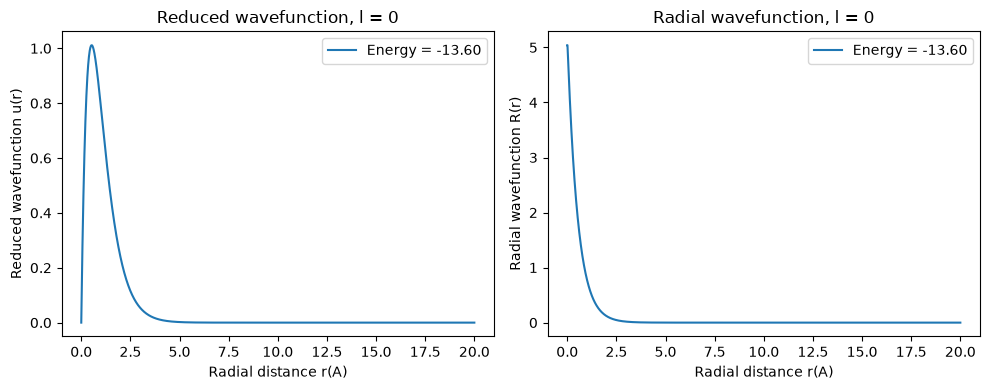

In [18]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,4))

ax1.plot(full_grid,phi_normalized,label=f"Energy = {energy_value:.2f}")
ax1.set_xlabel("Radial distance r(A)")
ax1.set_ylabel("Reduced wavefunction u(r)")
ax1.set_title(f"Reduced wavefunction, l = {l}")
ax1.legend()

ax2.plot(full_grid,R_final,label=f"Energy = {energy_value:.2f}")
ax2.set_xlabel("Radial distance r(A)")
ax2.set_ylabel("Radial wavefunction R(r)")
ax2.set_title(f"Radial wavefunction, l = {l}")
ax2.legend()

plt.tight_layout()
plt.show()

In [19]:
def same_l_different_n(ri,rf,interior_points,l,state_names):
    states=len(state_names)

    fig,(ax1,ax2)=plt.subplots(2,1,figsize=(10,9))

    for state_index in range(states):
        n=l+1+state_index

        grid,u_norm,energy,r_final=solve_potential(ri,rf,interior_points,l,state_index)

        label=f"{state_names[state_index]} (n={n}, E={energy:.2f} eV)"

        ax1.plot(grid,u_norm,label=label)
        ax2.plot(grid,r_final,label=label)

    ax1.set_xlim(0,30)
    ax1.set_xlabel("Radial distance r (Å)")
    ax1.set_ylabel("Reduced wavefunction u(r)")
    ax1.set_title(f"Reduced wavefunctions, l = {l}")
    ax1.legend()

    ax2.set_xlim(0,30)
    ax2.set_xlabel("Radial distance r (Å)")
    ax2.set_ylabel("Radial wavefunction R(r)")
    ax2.set_title(f"Radial wavefunctions, l = {l}")
    ax2.legend()

    plt.tight_layout()
    plt.show()

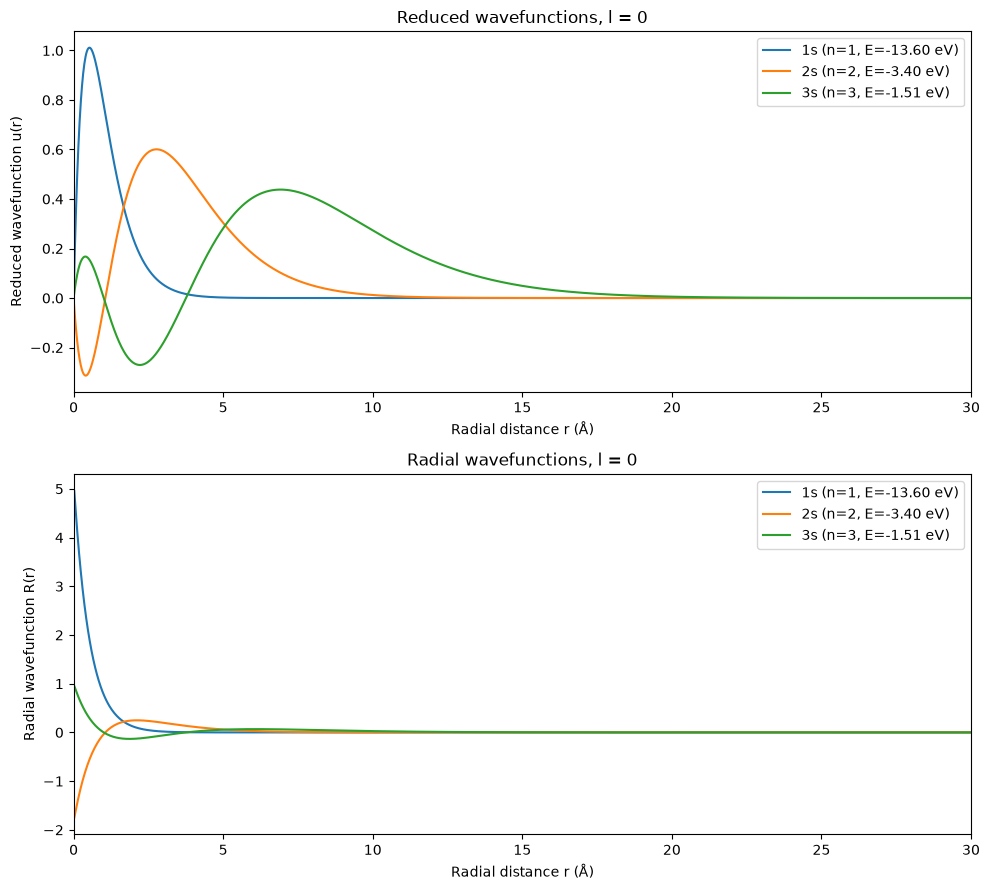

In [20]:
ri = 1e-4 
rf = 40.0
interior_points = 2000
l = 0
state_names = ["1s","2s","3s"]
same_l_different_n(ri,rf,interior_points,l,state_names)

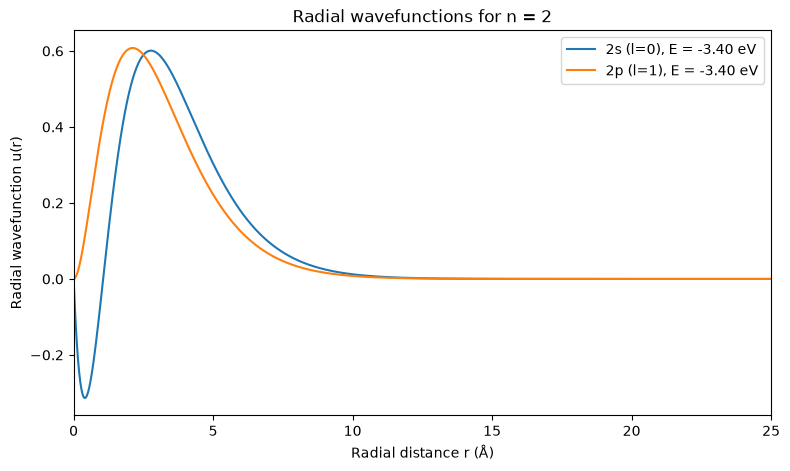

In [21]:
ri = 1e-4
rf = 40
interior_points = 2000
n = 2

labels = ["2s (l=0)", "2p (l=1)"]

plt.figure(figsize=(9,5))

for l in range(n):
    state_index = n-l-1
    grid,u_norm,energy,r_final = solve_potential(ri,rf,interior_points,l,state_index)
    plt.plot(grid,u_norm,label=f"{labels[l]}, E = {energy:.2f} eV")

plt.xlim(0,25)
plt.xlabel("Radial distance r (Å)")
plt.ylabel("Radial wavefunction u(r)")
plt.title(f"Radial wavefunctions for n = {n}")
plt.legend()
plt.show()